In [1]:
from dataloader import load_all_data
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'''\usepackage{libertine}\usepackage{fontawesome5}\usepackage{xcolor}'''
plt.rcParams['ps.usedistiller'] = 'xpdf'
import seaborn as sns
sns.set_theme(style='ticks')
from statannotations.Annotator import Annotator

In [2]:
colors = ['#c26f6d', '#d9a6a4', '#f2dfdd', '#e4e5eb', '#aab8d0', '#6e90bf']
interfaces = {
    'pointwise':        'UI1',
    'pairwise':         'UI2',
    'listwise-rating':  'UI3',
    'listwise-notie':   'UI4',
    'listwise-cantie':  'UI5',
    'listwise-ranking': 'UI6',
}

df_begins, df_all, df_finishs, df_demographic = load_all_data()

pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking
pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking


## Aggregate Decison Time

In [3]:
def aggregate_decision_time(df):
    # compute pointwise decision time
    df_pointwise = df[df.interface == 'pointwise']
    for idx, row in df_pointwise.iterrows():
        if row.timeLastRating == 0: # use submit time if no rating time.
            df_pointwise.loc[idx, 'timeLastRating'] = row.timeSubmit
    df_pointwise['decision_time'] = (pd.to_datetime(df_pointwise.timeLastRating, origin='unix', unit='ms') - pd.to_datetime(df_pointwise.timePresent, origin='unix', unit='ms')) / np.timedelta64(1, 's')

    # compute pairwise decision time
    df_pairwise = df[df.interface == 'pairwise']
    df_pairwise['decision_time'] = (pd.to_datetime(df_pairwise.timeLastRating, origin='unix', unit='ms') - pd.to_datetime(df_pairwise.timePresent, origin='unix', unit='ms')) / np.timedelta64(1, 's')

    # compute listwise-rating decision time
    df_listwise_rating = df[df.interface == 'listwise-rating']
    for idx, row in df_listwise_rating.iterrows():
        all = []
        for t in row.timeLastRating:
            if t == 0:
                t = row.timeSubmit
            all.append((pd.to_datetime(t, origin='unix', unit='ms') - pd.to_datetime(row.timePresent, origin='unix', unit='ms')) / np.timedelta64(1, 's'))
        df_listwise_rating.loc[idx, 'decision_time'] = np.max(all)

    # compute listwise-notie decision time
    df_listwise_notie = df[df.interface == 'listwise-notie']
    for idx, row in df_listwise_notie.iterrows():
        t = row.rating[-1]['timestamp']
        df_listwise_notie.loc[idx, 'decision_time'] = (pd.to_datetime(t, origin='unix', unit='ms') - pd.to_datetime(row.timePresent, origin='unix', unit='ms')) / np.timedelta64(1, 's')

    # compute listwise-cantie decision time
    df_listwise_cantie = df[df.interface == 'listwise-cantie']
    for idx, row in df_listwise_cantie.iterrows():
        t = row.rating[-1]['timestamp']
        df_listwise_cantie.loc[idx, 'decision_time'] = (pd.to_datetime(t, origin='unix', unit='ms') - pd.to_datetime(row.timePresent, origin='unix', unit='ms')) / np.timedelta64(1, 's')

    # compute listwise-ranking decision time
    df_listwise_ranking = df[df.interface == 'listwise-ranking']
    for idx, row in df_listwise_ranking.iterrows():
        t = row.rating[-1]['timestamp']
        df_listwise_ranking.loc[idx, 'decision_time'] = (pd.to_datetime(t, origin='unix', unit='ms') - pd.to_datetime(row.timePresent, origin='unix', unit='ms')) / np.timedelta64(1, 's')

    # construct all decision time
    df_decision_time = pd.DataFrame(columns=['userID', 'interface', 'taskID', 'decision_time'])
    for idx, row in df_pointwise.iterrows():
        df_decision_time = df_decision_time.append({'interface': row.interface, 'taskID': row.taskID, 'decision_time': row.decision_time, 'userID': row.userID}, ignore_index=True)
    for idx, row in df_pairwise.iterrows():
        df_decision_time = df_decision_time.append({'interface': row.interface, 'taskID': row.taskID, 'decision_time': row.decision_time, 'userID': row.userID}, ignore_index=True)
    for idx, row in df_listwise_rating.iterrows():
        df_decision_time = df_decision_time.append({'interface': row.interface, 'taskID': row.taskID, 'decision_time': row.decision_time, 'userID': row.userID}, ignore_index=True)
    for idx, row in df_listwise_notie.iterrows():
        df_decision_time = df_decision_time.append({'interface': row.interface, 'taskID': row.taskID, 'decision_time': row.decision_time, 'userID': row.userID}, ignore_index=True)
    for idx, row in df_listwise_cantie.iterrows():
        df_decision_time = df_decision_time.append({'interface': row.interface, 'taskID': row.taskID, 'decision_time': row.decision_time, 'userID': row.userID}, ignore_index=True)
    for idx, row in df_listwise_ranking.iterrows():
        df_decision_time = df_decision_time.append({'interface': row.interface, 'taskID': row.taskID, 'decision_time': row.decision_time, 'userID': row.userID}, ignore_index=True)

    df_decision_time2 = df_decision_time.copy()
    for idx, row in df_decision_time.iterrows():
        if row.interface == 'pairwise':
            df_decision_time2.loc[idx, 'decision_time'] = row.decision_time / 2
        if 'listwise' in row.interface:
            df_decision_time2.loc[idx, 'decision_time'] = row.decision_time / 4

    return df_decision_time, df_decision_time2

df_decision_time_per_iter = pd.DataFrame(columns=['userID', 'interface', 'domain', 'taskID', 'decision_time'])
df_decision_time_per_item = pd.DataFrame(columns=['userID', 'interface', 'domain', 'taskID', 'decision_time'])

for domain in ['text', 'image']:
    df_iter, df_item = aggregate_decision_time(df_all[df_all.domain == domain])
    df_iter['domain'] = domain
    df_item['domain'] = domain
    df_decision_time_per_iter = df_decision_time_per_iter.append(df_iter, ignore_index=True)
    df_decision_time_per_item = df_decision_time_per_item.append(df_item, ignore_index=True)

df_decision_time_per_iter.to_csv('processed/decision_time_per_iter.csv', index=False)
df_decision_time_per_item.to_csv('processed/decision_time_per_item.csv', index=False)
df_decision_time_per_iter = df_decision_time_per_iter.groupby(['userID', 'interface', 'domain']).mean().reset_index()
df_decision_time_per_item = df_decision_time_per_item.groupby(['userID', 'interface', 'domain']).mean().reset_index()

## Decision Time per Iter (Distribution)

<Axes: xlabel='decision_time', ylabel='Count'>

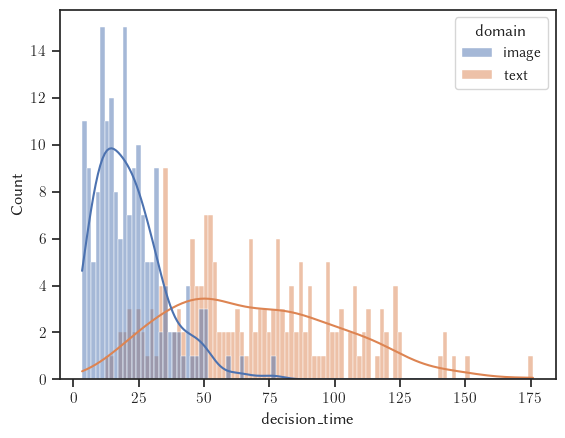

In [4]:
sns.histplot(data=df_decision_time_per_iter[df_decision_time_per_iter.decision_time < 200], x='decision_time', hue='domain', bins=100, kde=True)

<Axes: xlabel='decision_time', ylabel='Count'>

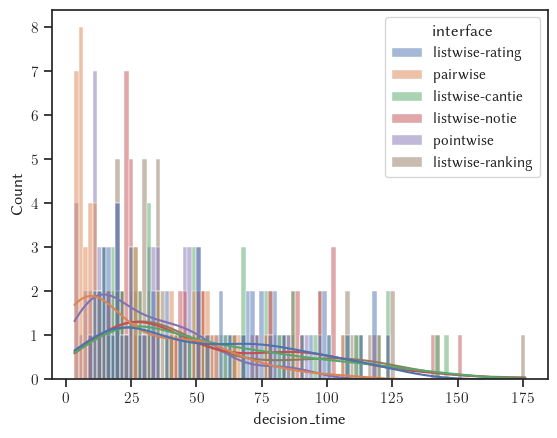

In [5]:
sns.histplot(data=df_decision_time_per_iter[df_decision_time_per_iter.decision_time < 200], x='decision_time', hue='interface', bins=100, kde=True)

## Decision Time per Item (Distribution)

<Axes: xlabel='decision_time', ylabel='Count'>

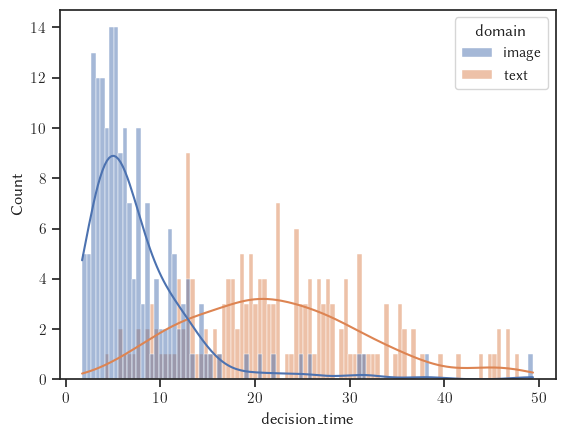

In [6]:
sns.histplot(data=df_decision_time_per_item[df_decision_time_per_item.decision_time < 50], x='decision_time', hue='domain', bins=100, kde=True)

<Axes: xlabel='decision_time', ylabel='Count'>

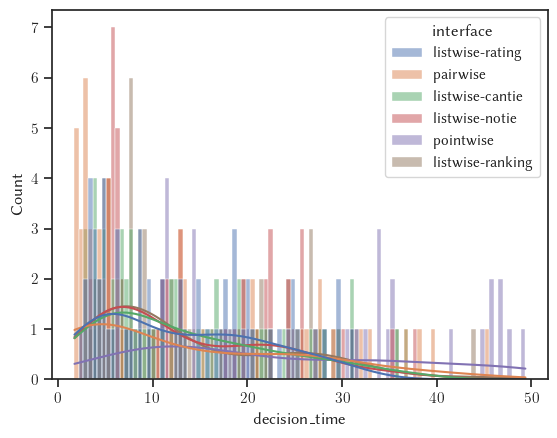

In [7]:
sns.histplot(data=df_decision_time_per_item[df_decision_time_per_item.decision_time < 50], x='decision_time', hue='interface', bins=100, kde=True)

In [8]:
from stats import pairwise_test

pairs = [
    ('pointwise', 'pairwise'),               # H1 : UI1 vs. UI2
    ('pointwise', 'listwise-rating'),        # H2a: UI1 vs. UI3
    ('pairwise',  'listwise-cantie'),        # H2b: UI2 vs. UI5
]

## H1 (UI1 vs. UI2), H2a (UI1 vs. UI3), H2b (UI2 vs. UI5)

### per Iter

In [9]:
pairwise_test(df_decision_time_per_iter[df_decision_time_per_iter.domain == 'text'], 'interface', 'decision_time', pairs=pairs)[['test_name', 'level1', 'level2', 'W', 'p', 'sig']]

,test_name,level1,level2,W,p,sig
0,t-test,pointwise,pairwise,0.08283643817087895,0.9342668231019571,n.s.
1,t-test,pointwise,listwise-rating,-5.885097577394868,2.1067274924552715e-07,***
2,t-test,pairwise,listwise-cantie,-4.7601715902974435,1.6439323551959255e-05,***


In [10]:
pairwise_test(df_decision_time_per_iter[df_decision_time_per_iter.domain == 'image'], 'interface', 'decision_time', pairs=pairs)[['test_name', 'level1', 'level2', 'p', 'sig']]

,test_name,level1,level2,p,sig
0,Wilcoxon rank-sum test,pointwise,pairwise,0.0009057489880540743,***
1,Wilcoxon rank-sum test,pointwise,listwise-rating,0.00015464045610778186,***
2,Wilcoxon rank-sum test,pairwise,listwise-cantie,6.845093399213902e-09,***


### per Item

In [11]:
pairwise_test(df_decision_time_per_item[df_decision_time_per_item.domain == 'text'], 'interface', 'decision_time', pairs=pairs)[['test_name', 'level1', 'level2', 'W', 'p', 'sig']]

,test_name,level1,level2,W,p,sig
0,t-test,pointwise,pairwise,5.73321595124155,7.375463386407684e-07,***
1,t-test,pointwise,listwise-rating,7.153606769194413,2.7417532178897462e-08,***
2,t-test,pairwise,listwise-cantie,1.1790442657223925,0.24319469997775522,n.s.


In [12]:
pairwise_test(df_decision_time_per_item[df_decision_time_per_item.domain == 'image'], 'interface', 'decision_time', pairs=pairs)[['test_name', 'level1', 'level2', 'p', 'sig']]

,test_name,level1,level2,p,sig
0,Wilcoxon rank-sum test,pointwise,pairwise,2.1376405159620326e-07,***
1,Wilcoxon rank-sum test,pointwise,listwise-rating,5.642192673980944e-06,***
2,Wilcoxon rank-sum test,pairwise,listwise-cantie,0.00027053383165251204,***


See LMMs:

    ('listwise-rating', 'listwise-cantie'),  # H3a
    ('listwise-notie', 'listwise-cantie'),   # H3b
    ('listwise-ranking', 'pairwise'),        # H4a
    ('listwise-ranking', 'listwise-rating'), # H4b
    ('listwise-ranking', 'listwise-notie'),  # H4c
    ('listwise-ranking', 'listwise-cantie'), # H4d

## Visualization - Text

p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pointwise vs. listwise-rating: H2a: ***
pairwise vs. listwise-cantie: H2b: ***
pairwise vs. listwise-ranking: H4a: ***
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pointwise vs. pairwise: H1: ***
pointwise vs. listwise-rating: H2a: ***


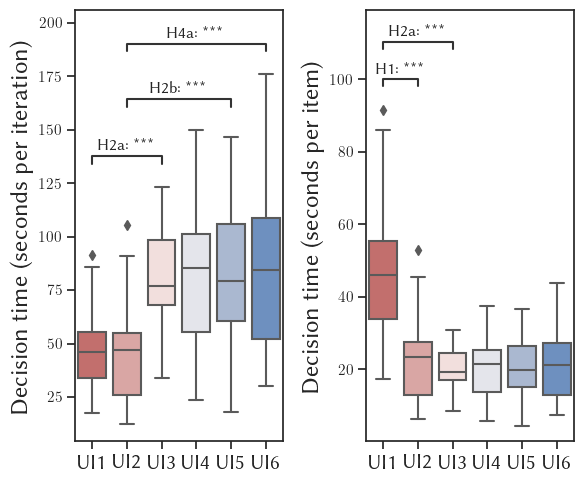

In [13]:
df_decision_time  = df_decision_time_per_iter[df_decision_time_per_iter.domain == 'text']
df_decision_time2 = df_decision_time_per_item[df_decision_time_per_item.domain == 'text']

fontsize=18
fig, axes = plt.subplots(1, 2, figsize=(6, 5))
sns.boxplot(ax=axes[0], data=df_decision_time, x='interface', y='decision_time', order=interfaces, palette=colors, saturation=1) #capsize=.2, errwidth=1, linewidth=1, edgecolor='black', errcolor='black')
axes[0].set_xticklabels(list(interfaces.values()), fontsize=15)
annot = Annotator(axes[0], [
    # ('pointwise', 'pairwise'),               # H1
    ('pointwise', 'listwise-rating'),        # H2a
    ('pairwise',  'listwise-cantie'),        # H2b
    # ('listwise-rating', 'listwise-cantie'),  # H3a
    # ('listwise-notie', 'listwise-cantie'),   # H3b
    ('listwise-ranking', 'pairwise'),        # H4a
    # ('listwise-ranking', 'listwise-rating'), # H4b
    # ('listwise-ranking', 'listwise-notie'),  # H4c
    # ('listwise-ranking', 'listwise-cantie'), # H4d
], data=df_decision_time, x='interface', y='decision_time', order=interfaces, show_non_significant=True)
# annot.configure(test='Mann-Whitney', text_format='star', loc='inside')
# annot.apply_and_annotate()
annot.set_custom_annotations(['H2a: ***', 'H2b: ***', 'H4a: ***'])
# annot.set_pvalues(pvalues=[0.08379160254791795, 2.1867180515685015e-20, 5.242350247686534e-29, 0.0018093614271365531, 0.4395178759704178, 0.014099696380418525, 0.26569877197591696, 0.31733690030205075])
annot.annotate()
axes[0].set_ylabel('Decision time (seconds per iteration)', fontsize=fontsize)
axes[0].set_xlabel('')


sns.boxplot(ax=axes[1], data=df_decision_time2, x='interface', y='decision_time', order=interfaces, palette=colors, saturation=1) # capsize=.1, errwidth=1, linewidth=1, edgecolor='black', errcolor='black')
axes[1].set_xticklabels(list(interfaces.values()), fontsize=15)
annot = Annotator(axes[1], [
    ('pointwise', 'pairwise'),               # H1
    ('pointwise', 'listwise-rating'),        # H2a
    # ('pairwise',  'listwise-cantie'),        # H2b
    # ('listwise-rating', 'listwise-cantie'),  # H3a
    # ('listwise-notie', 'listwise-cantie'),   # H3b
    # ('listwise-ranking', 'listwise-rating'), # H4a
    # ('listwise-ranking', 'listwise-notie'),  # H4b
    # ('listwise-ranking', 'listwise-cantie'), # H4c
], data=df_decision_time2, x='interface', y='decision_time', order=interfaces, show_non_significant=True)
# annot.configure(test='Mann-Whitney', text_format='star', loc='inside')
# annot.apply_and_annotate()
annot.set_custom_annotations(['H1: ***', 'H2a: ***'])
annot.annotate()
axes[1].set_ylabel('Decision time (seconds per item)', fontsize=fontsize)
axes[1].set_xlabel('')
plt.tight_layout()
plt.savefig('figures/decision_time_text.pdf', bbox_inches='tight')

## Visualization - Image

p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pointwise vs. pairwise: H1: ***
pointwise vs. listwise-rating: H2a: ***
pairwise vs. listwise-cantie: H2b: ***
pairwise vs. listwise-ranking: H4a: ***
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

pointwise vs. pairwise: H1: ***
pointwise vs. listwise-rating: H2a: ***


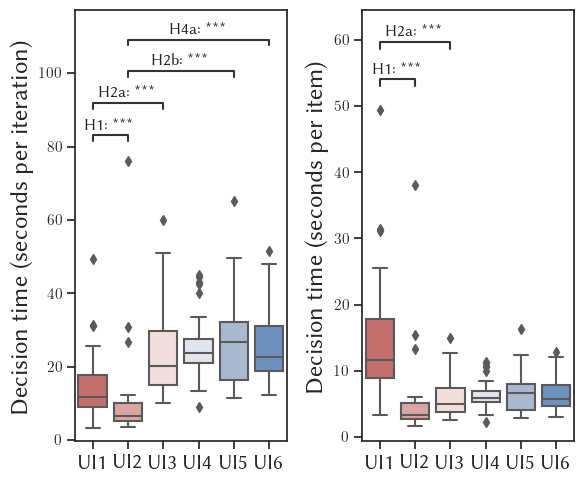

In [14]:
df_decision_time  = df_decision_time_per_iter[df_decision_time_per_iter.domain == 'image']
df_decision_time2 = df_decision_time_per_item[df_decision_time_per_item.domain == 'image']

fig, axes = plt.subplots(1, 2, figsize=(6, 5))
sns.boxplot(ax=axes[0], data=df_decision_time, x='interface', y='decision_time', order=interfaces, palette=colors, saturation=1 ) #, capsize=.2, errwidth=1, linewidth=1, edgecolor='black', errcolor='black')
axes[0].set_xticklabels(list(interfaces.values()), fontsize=15)
annot = Annotator(axes[0], [
    ('pointwise', 'pairwise'),               # H1
    ('pointwise', 'listwise-rating'),        # H2a
    ('pairwise',  'listwise-cantie'),        # H2b
    # ('listwise-rating', 'listwise-cantie'),  # H3a
    # ('listwise-notie', 'listwise-cantie'),   # H3b
    ('listwise-ranking', 'pairwise'),        # H4a
    # ('listwise-ranking', 'listwise-rating'), # H4b
    # ('listwise-ranking', 'listwise-notie'),  # H4c
    # ('listwise-ranking', 'listwise-cantie'), # H4d
], data=df_decision_time, x='interface', y='decision_time', order=interfaces, show_non_significant=True)
# annot.configure(test='Mann-Whitney', text_format='star', loc='inside')
# annot.apply_and_annotate()
annot.set_custom_annotations(['H1: ***', 'H2a: ***', 'H2b: ***', 'H4a: ***'])
# annot.set_pvalues(pvalues=[0.08379160254791795, 2.1867180515685015e-20, 5.242350247686534e-29, 0.0018093614271365531, 0.4395178759704178, 0.014099696380418525, 0.26569877197591696, 0.31733690030205075])
annot.annotate()
axes[0].set_ylabel('Decision time (seconds per iteration)', fontsize=18)
axes[0].set_xlabel('')


sns.boxplot(ax=axes[1], data=df_decision_time2, x='interface', y='decision_time', order=interfaces, palette=colors, saturation=1 ) #, capsize=.1, errwidth=1, linewidth=1, edgecolor='black', errcolor='black')
axes[1].set_xticklabels(list(interfaces.values()), fontsize=15)
annot = Annotator(axes[1], [
    ('pointwise', 'pairwise'),               # H1
    ('pointwise', 'listwise-rating'),        # H2a
    # ('pairwise',  'listwise-cantie'),        # H2b
    # ('listwise-rating', 'listwise-cantie'),  # H3a
    # ('listwise-notie', 'listwise-cantie'),   # H3b
    # ('listwise-ranking', 'listwise-rating'), # H4a
    # ('listwise-ranking', 'listwise-notie'),  # H4b
    # ('listwise-ranking', 'listwise-cantie'), # H4c
], data=df_decision_time2, x='interface', y='decision_time', order=interfaces, show_non_significant=True)
# annot.configure(test='Mann-Whitney', text_format='star', loc='inside')
# annot.apply_and_annotate()
annot.set_custom_annotations(['H1: ***', 'H2a: ***'])
annot.annotate()
axes[1].set_ylabel('Decision time (seconds per item)', fontsize=18)
axes[1].set_xlabel('')
plt.tight_layout()
plt.savefig('figures/decision_time_image.pdf', bbox_inches='tight')